# 04 กลยุทธ์การแบ่งข้อมูล (Split Strategy) — แบบชั่วคราวเพื่อการวิจัย

**เป้าหมาย:** แบ่งเหตุการณ์ที่ยืนยัน ACC_CODE แล้วตามเวลา และสร้าง panel จังหวัด×วัน **ชั่วคราว** เพื่อสาธิตความพร้อมของข้อมูลเท่านั้น (ไม่ใช่หน่วยสายทางของโมเดลจริง และจังหวัดที่รายงานยังไม่ได้ตรวจกับพิกัด)

**อินพุต:** `data/raw/accidents/source_manifest.json` (ตรวจ hash snapshot ดิบ) และ `data/interim/artifact_manifest.json` (ตรวจ hash ของ `cleaned_events.csv`, `diagnostic_rows.csv`, `quarantine.csv`, `possible_undercount_flags.csv` จาก Notebook 03)

**การแปลง:**
1. แบ่งตาม `event_date`: Train 2021–2023, Validation 2024, `reused_test_2025` (เคยถูกดูมาแล้ว ไม่ใช่ test อิสระ), `diagnostic_2026` แยกต่างหาก (ไม่มี ACC_CODE → **ไม่เป็นป้ายกำกับทั้งปี**)
2. พยากรณ์รายวัน: ออกพยากรณ์ 18:00 Asia/Bangkok ของวันก่อนหน้า เป้าหมาย = เที่ยงคืนถึงเที่ยงคืนถัดไปของวันท้องถิ่น (เขตเวลาเป็นสมมติฐาน)
3. ตัดป้ายกำกับที่ช่วงเวลาเป้าหมายสิ้นสุด **หลัง** เวลาออกพยากรณ์ครั้งแรกของ split ถัดไป (วันสุดท้ายของแต่ละ split)
4. ขอบเขตจังหวัด = จังหวัดที่พบใน **Train เท่านั้น**; เหตุการณ์ในจังหวัดนอกขอบเขตถูกบันทึกว่าถูกตัดออก
5. `y_recorded_count` = จำนวน `event_uid` ไม่ซ้ำที่ถูกเลือกและบันทึกไว้; ศูนย์ = ไม่มีเหตุการณ์ที่ถูกเลือก **ไม่ใช่การยืนยันว่าไม่มีอุบัติเหตุ**
6. วันที่จังหวัด (หรือ `*ALL*`) อยู่ใน `possible_undercount_flags.csv` → `possibly_undercounted = True` และ `training_eligible = False`; ธงเหล่านี้เป็นข้อมูลตรวจสอบ **ห้ามใช้เป็น feature**

**เอาต์พุต:** `data/processed/event_split_assignments.csv`, `data/processed/province_day_panel.csv`, `data/processed/split_artifact_manifest.json`; `reports/data/split/province_scope.csv`, `split_summary.csv`, `split_summary.json`, `daily_selected_counts_and_flags.png`

**การตรวจสอบ:** hash อินพุต, ลำดับเวลา, ขอบเขตจาก Train, บัญชีเหตุการณ์ = ผลรวม y, ธงทำให้ไม่ eligible, ไม่มีปี 2026 ใน panel

**ข้อจำกัด:** ความครบถ้วนของข้อมูลไม่ทราบ; ความล่าช้าของการรายงานไม่ทราบ; ไม่มีการ fit preprocessing ใด ๆ บน validation/test (สิ่งเดียวที่ "เรียนรู้" คือรายชื่อจังหวัดจาก Train); **ความพร้อมของโมเดลจริง = BLOCKED**

**สัญญาสำหรับขั้นถัดไป:** Notebook 05 ใช้ไฟล์ใน `data/processed/` ที่ hash ตรงกับ `split_artifact_manifest.json` เท่านั้น

In [1]:
import os, sys, json, hashlib
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

def find_backend_root():
    env = os.environ.get('ROADAWARE_BACKEND_ROOT')
    if env:
        return Path(env).resolve()
    here = Path.cwd().resolve()
    for c in [here, *here.parents]:
        if (c / 'backend' / 'config' / 'data_pipeline.json').is_file():
            return c / 'backend'
        if c.name == 'backend' and (c / 'config' / 'data_pipeline.json').is_file():
            return c
    raise FileNotFoundError('backend/config/data_pipeline.json not found from ' + str(here) + '; open the repository root or backend/notebooks')

def sha256_file(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for b in iter(lambda: f.read(chunk), b''):
            h.update(b)
    return h.hexdigest()

def verify_hashes(base, entries, label):
    bad = []
    for e in entries:
        p = base / e['path']
        if not p.is_file():
            bad.append('missing ' + str(p))
        elif sha256_file(p) != e['sha256']:
            bad.append('sha256 mismatch ' + str(p))
    if bad:
        raise RuntimeError(label + ' failed verification; rerun the producing notebook or use a fresh --output-dir:\n' + '\n'.join(bad))
    return len(entries)

BACKEND = find_backend_root()
REPO = BACKEND.parent
CFG = json.loads((BACKEND / 'config' / 'data_pipeline.json').read_text('utf-8'))
OUT = Path(os.environ.get('ROADAWARE_OUTPUT_DIR') or (BACKEND / CFG['output_root'])).resolve()
if os.environ.get('ROADAWARE_REQUIRE_VENV') == '1':
    assert Path(sys.prefix).resolve() == (REPO / '.venv').resolve(), 'kernel is not the project .venv: ' + sys.executable
RAW, INT, PROC = OUT / 'data' / 'raw' / 'accidents', OUT / 'data' / 'interim', OUT / 'data' / 'processed'
SPL = OUT / 'reports' / 'data' / 'split'
for d in (PROC, SPL):
    d.mkdir(parents=True, exist_ok=True)
man_file, art_file = RAW / 'source_manifest.json', INT / 'artifact_manifest.json'
for p, prod in ((man_file, '01_data_collection'), (art_file, '03_cleaning_preparation')):
    if not p.is_file():
        raise FileNotFoundError(str(p) + ' missing; run ' + prod + ' first')
MAN = json.loads(man_file.read_text('utf-8'))
ART = json.loads(art_file.read_text('utf-8'))
assert ART['input_source_manifest_sha256'] == sha256_file(man_file), 'interim artifacts were built from a different source manifest; rerun 03'
print('verified raw snapshots:', verify_hashes(OUT, MAN['files'], 'raw snapshot'))
print('verified interim artifacts:', verify_hashes(OUT, ART['files'], 'interim artifacts'))

verified raw snapshots: 6
verified interim artifacts: 8


In [2]:
# FUNCTIONS (notebook 04) - self-contained; tests execute this cell directly
import numpy as np, pandas as pd

CAL_FEATURES = ['day_of_week', 'month', 'day_of_month', 'day_of_year', 'is_weekend']
LABEL_ASSIGNMENTS = ['label_counted', 'label_counted_boundary_excluded']

def split_table(cfg):
    """Ordered label splits (inclusive local-date ranges) followed by the diagnostic split."""
    t = pd.DataFrame(cfg['splits'])[['name', 'start', 'end', 'status']]
    dg = cfg['diagnostic_split']
    diag_row = {'name': dg['name'], 'start': str(dg['year']) + '-01-01', 'end': str(dg['year']) + '-12-31', 'status': dg['status']}
    t = pd.concat([t, pd.DataFrame([diag_row])], ignore_index=True)
    t['start'] = pd.to_datetime(t['start'])
    t['end'] = pd.to_datetime(t['end'])
    t['is_label_split'] = t['name'] != dg['name']
    if not (t['start'].iloc[1:].to_numpy() > t['end'].iloc[:-1].to_numpy()).all():
        raise ValueError('split ranges overlap or are not chronological')
    return t

def assign_split(dates, splits):
    """Split name per date; 'unknown_date' when the date is missing/unparseable, never guessed."""
    d = pd.to_datetime(pd.Series(dates), errors='coerce')  # '' / unparseable -> NaT
    out = pd.Series('outside_split_ranges', index=d.index, dtype=object)
    out[d.isna()] = 'unknown_date'
    for name, start, end in zip(splits['name'], splits['start'], splits['end']):
        out[(d >= start) & (d <= end)] = name
    return out

def forecast_window(target_dates, issue_hour, days_before, tz):
    """issue_time = local midnight of target day - days_before + issue_hour; target = [midnight, next midnight)."""
    start = pd.to_datetime(pd.Series(target_dates)).dt.tz_localize(tz)
    w = pd.DataFrame({'issue_time': start - pd.Timedelta(days=days_before) + pd.Timedelta(hours=issue_hour),
                      'target_start': start, 'target_end': start + pd.Timedelta(days=1)}, index=start.index)
    if not (w['issue_time'] < w['target_start']).all():
        raise ValueError('issue time must precede the target window')
    return w

def first_issue_times(splits, issue_hour, days_before, tz):
    w = forecast_window(splits['start'], issue_hour, days_before, tz)
    return dict(zip(splits['name'], w['issue_time']))

def boundary_mask(split, target_end, split_order, first_issue):
    """True where a label window ends after the first issue time of the next chronological split."""
    nxt = {a: first_issue[b] for a, b in zip(split_order[:-1], split_order[1:])}
    return pd.Series([bool(s in nxt and e > nxt[s]) for s, e in zip(split, target_end)], index=split.index, dtype=bool)

def calendar_features(dates):
    d = pd.to_datetime(pd.Series(dates))
    return pd.DataFrame({'day_of_week': d.dt.dayofweek, 'month': d.dt.month, 'day_of_month': d.dt.day,
                         'day_of_year': d.dt.dayofyear, 'is_weekend': (d.dt.dayofweek >= 5).astype(int)}, index=d.index)

def train_scope(assign):
    """Province scope learned from Train label candidates only (the only fitted quantity in this notebook)."""
    m = (assign['split'] == 'train') & (assign['assignment'] == 'label_candidate') & (assign['province'] != '')
    return sorted(set(assign.loc[m, 'province']))

def finalize_assignments(assign, scope, label_splits, boundary_dates):
    """Resolve label candidates into counted / excluded; rows already excluded by notebook 03 keep their assignment."""
    a = assign.copy()
    cand = a['assignment'] == 'label_candidate'
    on_boundary = pd.to_datetime(a['event_date'], errors='coerce').isin(list(boundary_dates))
    res = pd.Series('label_counted', index=a.index, dtype=object)
    res[on_boundary] = 'label_counted_boundary_excluded'
    res[~a['province'].isin(scope)] = 'excluded_province_not_in_train_scope'
    off = ~a['split'].isin(label_splits)
    res[off] = 'excluded_' + a.loc[off, 'split'].astype(str)
    a.loc[cand, 'assignment'] = res[cand]
    return a

def apply_flags(panel, flags):
    """Mark province-days (or '*ALL*' provinces for a date) flagged by notebook 03. Audit columns only, never features."""
    f = flags.copy()
    f['target_date'] = pd.to_datetime(f['date'], errors='coerce')
    f = f[f['target_date'].notna()].copy()
    f['n_flagged_records'] = pd.to_numeric(f['n_flagged_records']).astype(int)
    per = f[f['province'] != '*ALL*'][['province', 'target_date', 'n_flagged_records', 'flag_reasons']]
    allp = f[f['province'] == '*ALL*'][['target_date', 'n_flagged_records', 'flag_reasons']].rename(
        columns={'n_flagged_records': 'n_all', 'flag_reasons': 'r_all'})
    p = panel.merge(per, on=['province', 'target_date'], how='left').merge(allp, on='target_date', how='left')
    has_p, has_a = p['n_flagged_records'].notna(), p['n_all'].notna()
    p['flag_scope'] = np.select([has_p & has_a, has_p, has_a], ['province+*ALL*', 'province', '*ALL*'], '')
    p['n_flagged_records'] = (p['n_flagged_records'].fillna(0) + p['n_all'].fillna(0)).astype(int)
    p['flag_reasons'] = [';'.join(sorted({t for v in (a, b) if isinstance(v, str) for t in v.split(';') if t}))
                         for a, b in zip(p['flag_reasons'], p['r_all'])]
    p['possibly_undercounted'] = p['n_flagged_records'] > 0
    return p.drop(columns=['n_all', 'r_all'])

def build_panel(assign, scope, splits, fc, tz, flags):
    """Provisional province x local-day panel over label splits; y = unique counted event_uid per cell."""
    lab = splits[splits['is_label_split']]
    days = pd.concat([pd.DataFrame({'split': n, 'target_date': pd.date_range(s, e, freq='D')})
                      for n, s, e in zip(lab['name'], lab['start'], lab['end'])], ignore_index=True)
    panel = days.merge(pd.DataFrame({'province': list(scope)}), how='cross')
    ev = assign[assign['assignment'].isin(LABEL_ASSIGNMENTS)].copy()
    ev['target_date'] = pd.to_datetime(ev['event_date'])
    y = ev.groupby(['province', 'target_date'])['event_uid'].nunique().rename('y_recorded_count').reset_index()
    panel = panel.merge(y, on=['province', 'target_date'], how='left')
    # zero = no selected recorded event in this cell; true accident absence / completeness is NOT verified
    panel['y_recorded_count'] = panel['y_recorded_count'].fillna(0).astype(int)
    panel = pd.concat([panel, forecast_window(panel['target_date'], fc['issue_hour_local'], fc['issue_days_before_target'], tz),
                       calendar_features(panel['target_date'])], axis=1)
    first = first_issue_times(splits, fc['issue_hour_local'], fc['issue_days_before_target'], tz)
    panel['boundary_excluded'] = boundary_mask(panel['split'], panel['target_end'], list(splits['name']), first)
    panel = apply_flags(panel, flags)
    panel['training_eligible'] = ~panel['boundary_excluded'] & ~panel['possibly_undercounted']
    panel['label_status'] = np.select([panel['boundary_excluded'], panel['possibly_undercounted'], panel['y_recorded_count'] == 0],
                                      ['boundary_excluded', 'possibly_undercounted', 'zero_selected_recorded_events'], 'selected_recorded_count')
    panel['completeness'] = 'unverified'
    return panel.sort_values(['target_date', 'province']).reset_index(drop=True)

In [3]:
rd = lambda n: pd.read_csv(INT / n, dtype=str, keep_default_na=False)
ret, diag, quar, flags = rd('cleaned_events.csv'), rd('diagnostic_rows.csv'), rd('quarantine.csv'), rd('possible_undercount_flags.csv')
SPLITS = split_table(CFG)
LABEL_SPLITS = list(SPLITS.loc[SPLITS['is_label_split'], 'name'])
FC, TZ = CFG['forecast'], CFG['timezone_assumption']
cols = ['event_uid', 'source_file', 'source_year', 'source_row', 'event_date', 'province']
parts = []
for df, kind in ((ret, 'label_candidate'), (diag, 'excluded_no_acc_code_diagnostic'), (quar, 'excluded_quarantined_in_03')):
    x = df[cols].copy()
    x['assignment'] = kind
    x['reasons'] = df['reasons'] if 'reasons' in df.columns else ''
    x['date_candidates'] = df['date_candidates'] if 'date_candidates' in df.columns else x['event_date']
    parts.append(x)
assign = pd.concat(parts, ignore_index=True)
assign['split'] = assign_split(assign['event_date'], SPLITS)
# excluded rows with neither a parsed date nor any candidate date cannot be placed on any province-day
assign['localizable'] = (assign['event_date'] != '') | (assign['date_candidates'] != '')
SPLITS.assign(first_issue_time=SPLITS['name'].map(first_issue_times(SPLITS, FC['issue_hour_local'], FC['issue_days_before_target'], TZ)))

,name,start,end,status,is_label_split,first_issue_time
0,train,2021-01-01,2023-12-31,provisional_research,True,2020-12-31 18:00:00+07:00
1,validation,2024-01-01,2024-12-31,provisional_research,True,2023-12-31 18:00:00+07:00
2,reused_test_2025,2025-01-01,2025-12-31,reused_previously_seen_not_independent,True,2024-12-31 18:00:00+07:00
3,diagnostic_2026,2026-01-01,2026-12-31,diagnostic_only_no_acc_code_not_a_label,False,2025-12-31 18:00:00+07:00


In [4]:
SCOPE = train_scope(assign)
first = first_issue_times(SPLITS, FC['issue_hour_local'], FC['issue_days_before_target'], TZ)
all_days = pd.concat([pd.Series(pd.date_range(s, e, freq='D')) for s, e in zip(SPLITS['start'], SPLITS['end'])], ignore_index=True)
bmask = boundary_mask(assign_split(all_days, SPLITS),
                      forecast_window(all_days, FC['issue_hour_local'], FC['issue_days_before_target'], TZ)['target_end'], list(SPLITS['name']), first)
BOUNDARY_DATES = set(all_days[bmask.to_numpy()])
assign = finalize_assignments(assign, SCOPE, LABEL_SPLITS, BOUNDARY_DATES)
panel = build_panel(assign, SCOPE, SPLITS, FC, TZ, flags)
elig = panel[['province', 'target_date', 'training_eligible']].rename(columns={'training_eligible': 'panel_training_eligible'})
elig['event_date'] = elig['target_date'].dt.strftime('%Y-%m-%d')
assign = assign.merge(elig.drop(columns='target_date'), on=['province', 'event_date'], how='left')
assign['panel_training_eligible'] = assign['panel_training_eligible'].eq(True)
print('province scope (from Train only):', len(SCOPE), '| boundary-excluded target dates:', sorted(d.date().isoformat() for d in BOUNDARY_DATES))
pd.crosstab(assign['assignment'], assign['split'], margins=True)

province scope (from Train only): 77 | boundary-excluded target dates: ['2023-12-31', '2024-12-31', '2025-12-31']


split,diagnostic_2026,reused_test_2025,train,unknown_date,validation,All
assignment,,,,,,
excluded_no_acc_code_diagnostic,9205,0,0,6034,0,15239
excluded_quarantined_in_03,0,173,2527,22976,2164,27840
label_counted,0,23294,38966,0,21679,83939
label_counted_boundary_excluded,0,248,0,0,109,357
All,9205,23715,41493,29010,23952,127375


,target_days,provinces,panel_rows,selected_recorded_events,boundary_excluded_rows,possibly_undercounted_rows,training_eligible_rows,zero_count_rows,unique_counted_event_uid,eligible_zero_rows,status
split,,,,,,,,,,,
train,1095,77,84315,38966,77,20558,63757,62499,38966,42761,provisional_research
validation,366,77,28182,21788,77,20297,7885,16684,21788,4457,provisional_research
reused_test_2025,365,77,28105,23542,77,523,27506,15833,23542,15722,reused_previously_seen_not_independent


split,diagnostic_2026,reused_test_2025,train,unknown_date,validation
assignment,,,,,
excluded_no_acc_code_diagnostic,9205,0,0,6034,0
excluded_quarantined_in_03,0,173,2527,22976,2164


excluded rows that cannot be localized to any date (cannot be flagged on a province-day), by BE source year: {}


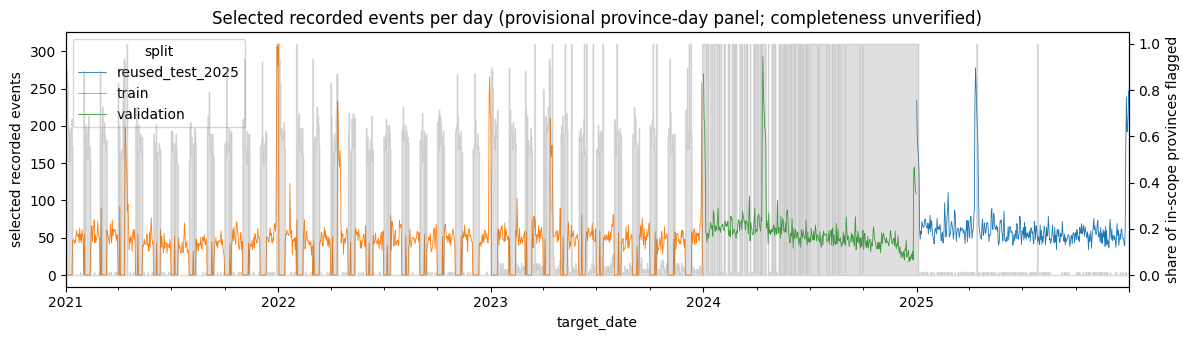

In [5]:
lab_ev = assign[assign['assignment'].isin(LABEL_ASSIGNMENTS)]
summary = panel.groupby('split', sort=False).agg(
    target_days=('target_date', 'nunique'), provinces=('province', 'nunique'), panel_rows=('province', 'size'),
    selected_recorded_events=('y_recorded_count', 'sum'), boundary_excluded_rows=('boundary_excluded', 'sum'),
    possibly_undercounted_rows=('possibly_undercounted', 'sum'), training_eligible_rows=('training_eligible', 'sum'),
    zero_count_rows=('y_recorded_count', lambda s: int((s == 0).sum())))
summary['unique_counted_event_uid'] = lab_ev.groupby('split')['event_uid'].nunique().reindex(summary.index).fillna(0).astype(int)
summary['eligible_zero_rows'] = panel[panel['training_eligible']].groupby('split')['y_recorded_count'].apply(lambda s: int((s == 0).sum())).reindex(summary.index).fillna(0).astype(int)
summary['status'] = SPLITS.set_index('name')['status'].reindex(summary.index)
excl = assign[~assign['assignment'].isin(LABEL_ASSIGNMENTS)]
excl_table = pd.crosstab(excl['assignment'], excl['split'])
unlocalized = excl[~excl['localizable']].groupby('source_year').size()
oos = assign[assign['assignment'] == 'excluded_province_not_in_train_scope']
scope_df = pd.DataFrame({'province': SCOPE, 'in_scope': True})
scope_df['train_events'] = scope_df['province'].map(lab_ev[lab_ev['split'] == 'train'].groupby('province')['event_uid'].nunique()).fillna(0).astype(int)
oos_df = pd.crosstab(oos['province'].replace('', '(empty)'), oos['split']).reset_index() if len(oos) else pd.DataFrame(columns=['province'])
scope_out = pd.concat([scope_df, oos_df.assign(in_scope=False)], ignore_index=True, sort=False)
display(summary); display(excl_table)
print('excluded rows that cannot be localized to any date (cannot be flagged on a province-day), by BE source year:', unlocalized.to_dict())
fig, ax = plt.subplots(figsize=(12, 3.5))
daily = panel.groupby(['target_date', 'split'])['y_recorded_count'].sum().unstack()
daily.plot(ax=ax, lw=0.6, title='Selected recorded events per day (provisional province-day panel; completeness unverified)')
fl = panel.groupby('target_date')['possibly_undercounted'].mean()
ax2 = ax.twinx()
ax2.fill_between(fl.index, fl.values, color='grey', alpha=0.25, step='mid')
ax2.set_ylabel('share of in-scope provinces flagged')
ax.set_ylabel('selected recorded events')
fig.tight_layout(); fig.savefig(SPL / 'daily_selected_counts_and_flags.png', dpi=110); plt.show()

In [6]:
iso = lambda s: s.map(lambda t: t.isoformat())
panel_out = panel.assign(target_date=panel['target_date'].dt.strftime('%Y-%m-%d'), issue_time=iso(panel['issue_time']),
                         target_start=iso(panel['target_start']), target_end=iso(panel['target_end']))
proc_files = {'event_split_assignments.csv': assign, 'province_day_panel.csv': panel_out}
for n, df in proc_files.items():
    df.to_csv(PROC / n, index=False)
summary.reset_index().to_csv(SPL / 'split_summary.csv', index=False)
scope_out.to_csv(SPL / 'province_scope.csv', index=False)
split_json = {
    'producer': '04_split_strategy', 'unit_status': FC['unit_status'], 'timezone_assumption': TZ,
    'issue_rule': '%02d:00 local, %d day(s) before the target local day' % (FC['issue_hour_local'], FC['issue_days_before_target']),
    'splits': json.loads(SPLITS.assign(start=SPLITS['start'].dt.strftime('%Y-%m-%d'), end=SPLITS['end'].dt.strftime('%Y-%m-%d')).to_json(orient='records')),
    'first_issue_time': {k: v.isoformat() for k, v in first.items()},
    'boundary_excluded_target_dates': sorted(d.date().isoformat() for d in BOUNDARY_DATES),
    'province_scope_size': len(SCOPE), 'province_scope_source': 'train label candidates only',
    'summary_by_split': json.loads(summary.reset_index().to_json(orient='records')),
    'excluded_rows_by_assignment': {k: int(v) for k, v in excl['assignment'].value_counts().items()},
    'excluded_rows_not_localizable_by_source_year': {str(k): int(v) for k, v in unlocalized.items()},
    'not_localizable_note': 'these excluded rows have no parsed or candidate date, so no province-day can be flagged for them; undercount is possible on unknown days',
    'diagnostic_2026_note': 'whole no-ID 2026 file is diagnostic only and never used as labels',
    'count_semantics': 'y_recorded_count = unique selected recorded event_uid; zero != verified absence; completeness unverified',
    'flags_are_features': False, 'preprocessing_fitted_on': 'train only (province scope); nothing fitted on validation/test',
    'final_model_readiness': 'BLOCKED',
    'blockers': CFG['unresolved_blockers'],
}
(SPL / 'split_summary.json').write_text(json.dumps(split_json, ensure_ascii=False, indent=2, default=str), 'utf-8')
inputs = [{'path': p.relative_to(OUT).as_posix(), 'sha256': sha256_file(p)} for p in (man_file, art_file)] + ART['files']
outputs = [{'path': 'data/processed/' + n, 'sha256': sha256_file(PROC / n)} for n in proc_files]
outputs += [{'path': 'reports/data/split/' + n, 'sha256': sha256_file(SPL / n)} for n in ('split_summary.csv', 'province_scope.csv', 'split_summary.json')]
split_man = {'producer': '04_split_strategy', 'inputs': inputs, 'files': outputs}
(PROC / 'split_artifact_manifest.json').write_text(json.dumps(split_man, indent=2), 'utf-8')
pd.DataFrame(outputs)

,path,sha256
0,data/processed/event_split_assignments.csv,af1405a03293c2fb7a43030c2375e6bafa3ce0b29a0f90...
1,data/processed/province_day_panel.csv,22604a280264d55e2caacb21da2e135ca8896b849457b8...
2,reports/data/split/split_summary.csv,a5d47385a4e6b52e6c38f9d1f675d9647d14ab6f90c92d...
3,reports/data/split/province_scope.csv,87f3063c46d4b8086cdb58ab26f194120c6c38e51350d5...
4,reports/data/split/split_summary.json,bf88e52e6c6a9b9969159d6a3010d00cf35a8fd18913f6...


In [7]:
assert len(assign) == len(ret) + len(diag) + len(quar), 'every retained/diagnostic/quarantined row needs exactly one assignment'
assert assign.groupby(['source_file', 'source_row']).size().max() == 1
assert int(panel['y_recorded_count'].sum()) == lab_ev['event_uid'].nunique() == len(lab_ev), 'panel total != unique counted events'
assert len(panel) == len(SCOPE) * panel['target_date'].nunique()
assert set(panel['split']) == set(LABEL_SPLITS) and CFG['diagnostic_split']['name'] not in set(panel['split'])
assert not assign.loc[assign['split'] == CFG['diagnostic_split']['name'], 'assignment'].isin(LABEL_ASSIGNMENTS).any(), '2026 used as label'
assert not lab_ev['event_uid'].str.startswith('diag:').any()
assert set(SCOPE) <= set(assign.loc[(assign['split'] == 'train') & assign['assignment'].isin(LABEL_ASSIGNMENTS), 'province']), 'scope not from train'
for a, b in zip(LABEL_SPLITS[:-1], LABEL_SPLITS[1:]):
    pa, pb = panel[panel['split'] == a], panel[panel['split'] == b]
    assert pa['target_date'].max() < pb['target_date'].min()
    assert pa.loc[~pa['boundary_excluded'], 'target_end'].max() <= first[b], a + ' label overlaps ' + b + ' issue time'
assert not panel.loc[panel['possibly_undercounted'], 'training_eligible'].any(), 'flagged province-day marked eligible'
assert (panel['issue_time'] < panel['target_start']).all()
assert verify_hashes(OUT, split_man['files'], 'split artifacts') == len(outputs)
print('Split checks passed. They verify implemented accounting/ordering only; completeness, reporting delay and route-level validity remain unverified.')
print('final_model_readiness: BLOCKED')

Split checks passed. They verify implemented accounting/ordering only; completeness, reporting delay and route-level validity remain unverified.
final_model_readiness: BLOCKED


## ข้อจำกัดและสัญญาสำหรับขั้นถัดไป

- Panel จังหวัด×วันเป็น **การสาธิตความพร้อมของข้อมูลแบบชั่วคราว** ไม่ใช่หน่วยสายทางของโมเดลจริง; จังหวัดเป็นค่าที่รายงาน ยังไม่ตรวจกับพิกัด
- `y_recorded_count` คือจำนวนเหตุการณ์ที่ถูกเลือกและบันทึกไว้ ไม่ใช่จำนวนอุบัติเหตุจริง; ค่า 0 ≠ ไม่มีอุบัติเหตุ; ความครบถ้วน **ไม่ได้ตรวจสอบ** (`completeness = unverified`)
- วันที่ถูกธง `possibly_undercounted` ไม่ eligible; แถวที่ถูกตัดออกโดยไม่มีวันที่ใดเลยไม่สามารถวางลงวันได้ จึงอาจมีการนับขาดในวันที่ไม่ทราบ (ดู `excluded_rows_not_localizable_by_source_year`)
- `reused_test_2025` เคยถูกดูมาแล้ว จึง **ไม่ใช่ test อิสระ**; ปี 2026 ใช้เพื่อวินิจฉัยเท่านั้น
- ไม่มีการเทรนหรือปรับแต่งโมเดลใน notebook นี้; **ความพร้อมของโมเดลจริง = BLOCKED**
- Notebook 05 ตรวจ leakage จาก `data/processed/*` ที่ hash ตรงกับ `split_artifact_manifest.json`